# 03 · One-stage detectors: RetinaNet (anchor-based) and YOLO11s (anchor-free)

* `retina_base` / `retina_a12` – RetinaNet v2, default anchors vs anchors 12-192 (EDA: 99% coverage).
* `yolo_base` – YOLO11s, 1344 px.
* `yolo_nwd` – box loss `0.5·(1−CIoU) + 0.5·(1−NWD)`, normalised Wasserstein distance for tiny boxes.
* `yolo_p2` – extra stride-4 (P2) detection head, initialised from `yolo11s.pt` (297 of 593 tensors transfer).
* `yolo_1920` – input size 1920.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..").resolve() / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from hw2 import CLASSES
from hw2.analysis import load_run, metrics_table, curve, error_breakdown, worst_frames, draw
from hw2.data import find_data_root, fold_frames, load_all, make_folds, subsample

sns.set_theme(style="whitegrid", context="notebook")
IMG = Path("../images"); IMG.mkdir(exist_ok=True)
frames, boxes = load_all(find_data_root())
val = subsample(fold_frames(frames, make_folds(frames), 0), 4)   # the validation frames every run was scored on
vpath = val.set_index("key").path
vboxes = boxes[boxes.key.isin(set(val.key))]


In [2]:
def table(runs):
    return metrics_table(runs).round(4)

def per_class(runs):
    rows = {r: {c: json.load(open(f"../runs/{r}/metrics.json"))[f"AP_{c}"] for c in CLASSES} for r in runs}
    return pd.DataFrame(rows).T.round(3)

def plot_curves(runs, title, fname, x="epoch"):
    fig, ax = plt.subplots(figsize=(7, 4))
    for r in runs:
        c = curve(load_run(r))
        ax.plot(c[x], c.mAP, marker="o", ms=4, label=r)
    ax.set_xlabel(x if x == "epoch" else "training time, min"); ax.set_ylabel("mAP@[.5:.95] on fold 0"); ax.set_title(title); ax.legend()
    fig.tight_layout(); fig.savefig(IMG / fname, dpi=140); plt.show()

def breakdown(runs, thr=0.3):
    rows = {}
    for r in runs:
        p = load_run(r)["val_preds"]
        rows[r] = error_breakdown(p, vboxes, val.key, score_thr=thr)
    return pd.DataFrame(rows).T

def crop_window(gt, W, H, frac=0.45):
    """The (frac*W x frac*H) window that holds the most ground-truth centres."""
    g = gt[gt.ignore == 0]
    cx, cy = g.x + g.w / 2, g.y + g.h / 2
    w, h = int(W * frac), int(H * frac)
    best = max(((x0, y0) for x0 in np.linspace(0, W - w, 4).astype(int) for y0 in np.linspace(0, H - h, 4).astype(int)),
               key=lambda p: ((cx >= p[0]) & (cx < p[0] + w) & (cy >= p[1]) & (cy < p[1] + h)).sum())
    return best[0], best[1], best[0] + w, best[1] + h

def show_cases(runs, cases, fname, thr=0.3):
    """One row per failure case, one column per run: green = ground truth, grey = ignored region, red = detections."""
    fig, axes = plt.subplots(len(cases), len(runs), figsize=(6.5 * len(runs), 4.2 * len(cases)), squeeze=False)
    preds = {r: load_run(r)["val_preds"] for r in runs}
    for i, (key, why) in enumerate(cases):
        gt = vboxes[vboxes.key == key]
        fr = val.set_index("key").loc[key]
        crop = crop_window(gt, int(fr.width), int(fr.height))
        for j, r in enumerate(runs):
            axes[i, j].imshow(draw(vpath[key], preds[r][preds[r].key == key], gt, thr, crop))
            axes[i, j].set_title(f"{r}: {why}", fontsize=9); axes[i, j].axis("off")
    fig.tight_layout(); fig.savefig(IMG / fname, dpi=120); plt.show()

def pick_cases(run, n_sample=150):
    """Three failure types for one run: missed small objects, class confusions, false alarms."""
    p = load_run(run)["val_preds"]
    w = worst_frames(p, vboxes, val.key, n_sample=n_sample)
    miss = w.sort_values("missed_small", ascending=False).index[0]
    conf = w[w.index != miss].sort_values("cls", ascending=False).index[0]
    fp = w[~w.index.isin([miss, conf])].sort_values("background", ascending=False).index[0]
    return w, [(miss, "most missed small objects"), (conf, "most class confusions"), (fp, "most background false alarms")]


## Metrics

In [3]:
R = ['retina_base', 'retina_a12', 'yolo_base', 'yolo_nwd', 'yolo_p2', 'yolo_1920']
table(R)

,mAP,AP50,AP75,AP_small,AP_medium,AP_large,AR500,fps,train_min
run,,,,,,,,,
retina_base,0.2287,0.4175,0.2221,0.0454,0.1596,0.4204,0.3757,18.57,91.7
retina_a12,0.1834,0.3992,0.1476,0.0664,0.1385,0.2766,0.4129,19.18,86.7
yolo_base,0.2449,0.4427,0.2407,0.0797,0.1736,0.4004,0.3657,74.91,29.2
yolo_nwd,0.2489,0.4496,0.2438,0.0739,0.1694,0.4253,0.3751,76.27,29.0
yolo_p2,0.2178,0.4301,0.1953,0.0756,0.1657,0.3524,0.3929,50.85,51.7
yolo_1920,0.2511,0.4517,0.2435,0.0837,0.1886,0.4131,0.3771,37.26,58.6


In [4]:
per_class(R)

,person,bicycle,car,van,truck,tricycle,bus,motor
retina_base,0.177,0.052,0.443,0.181,0.162,0.257,0.481,0.078
retina_a12,0.155,0.058,0.421,0.138,0.081,0.174,0.379,0.075
yolo_base,0.218,0.069,0.500,0.174,0.172,0.269,0.458,0.107
yolo_nwd,0.214,0.058,0.499,0.198,0.170,0.265,0.477,0.117
yolo_p2,0.200,0.074,0.487,0.170,0.112,0.256,0.351,0.106
yolo_1920,0.215,0.078,0.512,0.210,0.183,0.270,0.424,0.123


## Training curves

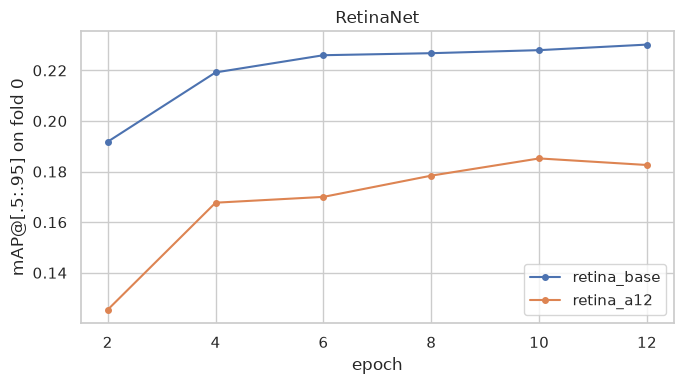

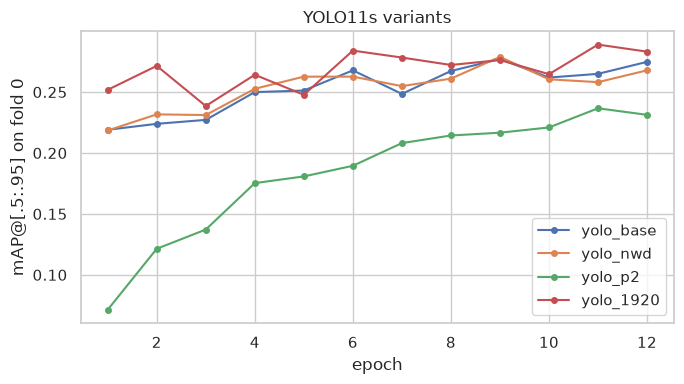

In [5]:
plot_curves(['retina_base', 'retina_a12'], 'RetinaNet', 'curve_retina.png')
plot_curves(['yolo_base', 'yolo_nwd', 'yolo_p2', 'yolo_1920'], 'YOLO11s variants', 'curve_yolo.png')

## Speed / accuracy

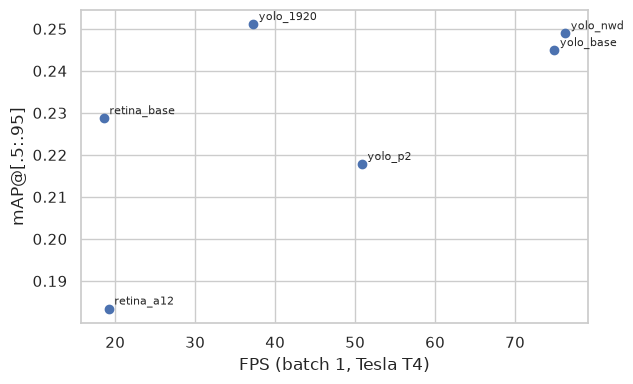

In [6]:
t = table(R)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(t.fps, t.mAP)
for r, row in t.iterrows(): ax.annotate(r, (row.fps, row.mAP), fontsize=8, xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('FPS (batch 1, Tesla T4)'); ax.set_ylabel('mAP@[.5:.95]'); fig.tight_layout(); fig.savefig(IMG / 'speed_one_stage.png', dpi=140)

## Where the errors are

In [7]:
bd = breakdown(['retina_base', 'retina_a12', 'yolo_base', 'yolo_nwd', 'yolo_p2']); bd

,tp,duplicate,cls,loc,ignored,background,missed_small,missed_medium,missed_large,recall_small,recall_medium,recall_large
retina_base,42336.0,1850.0,11124.0,8377.0,13836.0,10068.0,9027.0,16306.0,862.0,0.288,0.636,0.922
retina_a12,42665.0,1860.0,9565.0,9245.0,15961.0,9885.0,8554.0,15619.0,1693.0,0.325,0.652,0.847
yolo_base,43801.0,406.0,5874.0,3846.0,11438.0,7083.0,8252.0,15239.0,1239.0,0.349,0.660,0.888
yolo_nwd,43239.0,355.0,5469.0,3444.0,10854.0,6583.0,8638.0,15327.0,1327.0,0.318,0.658,0.880
yolo_p2,42167.0,427.0,5653.0,3385.0,10997.0,6330.0,8876.0,15895.0,1593.0,0.300,0.645,0.856


## Failure cases (3)

[('uav0000124_00944_v_0000185', 'most missed small objects'), ('uav0000288_00001_v_0000033', 'most class confusions'), ('uav0000140_01590_v_0000189', 'most background false alarms')]


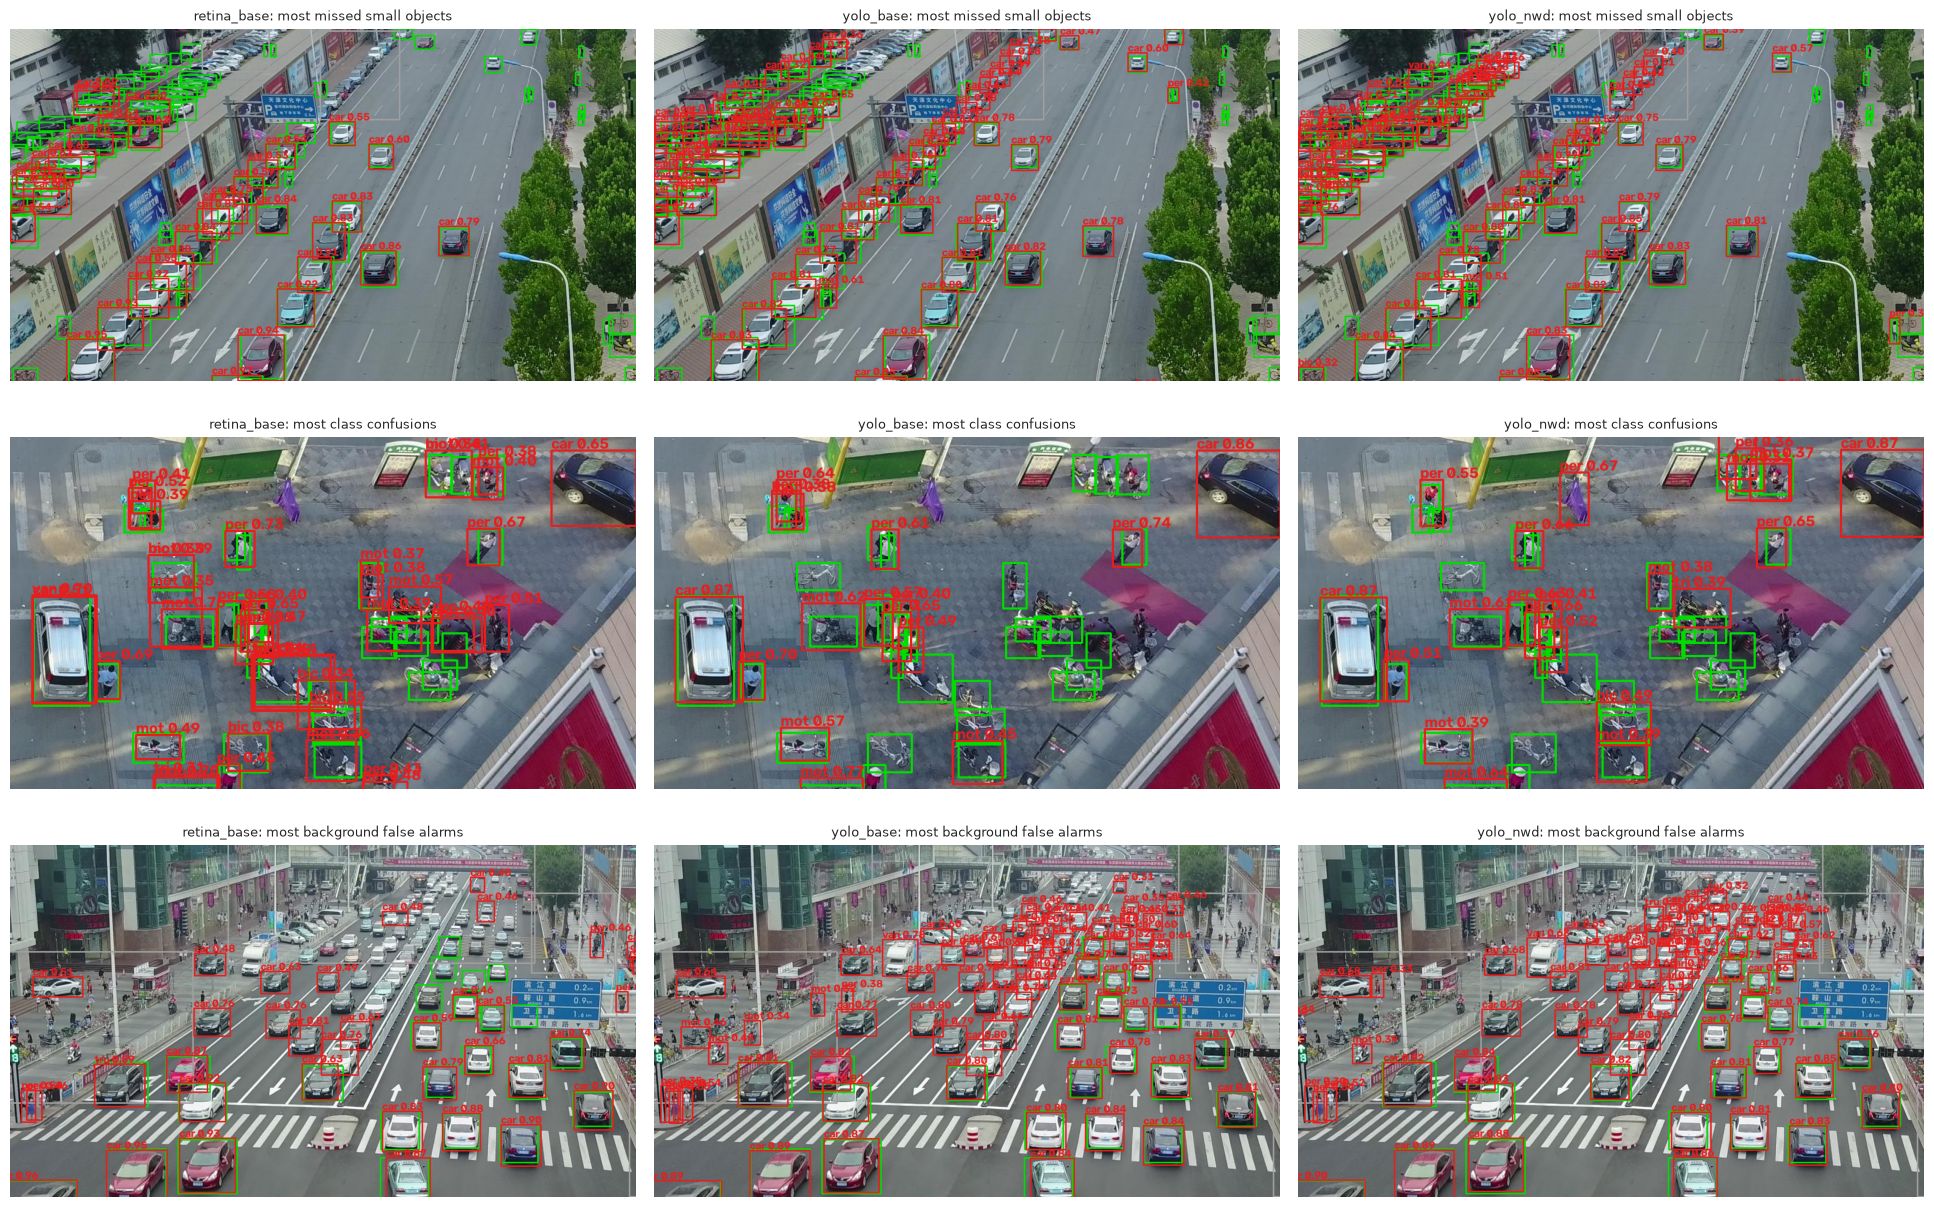

In [8]:
w, cases = pick_cases('yolo_base')
print(cases)
show_cases(['retina_base', 'yolo_base', 'yolo_nwd'], cases, 'fail_onestage.png')